In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
from statistics import NormalDist
from datetime import timedelta
import time

from experiment_runner import run_monte_carlo, run_parallel_monte_carlo
from Haar.Haar_matrix import Haar_matrix
from Haar_Basis_Algorithm import Haar_Basis_Algorithm
from NLMS import NLMS_Algorithm
from generators.generators import ARGenerator, GaussianNoiseGenerator
from line_echo.lineecho import m1

In [2]:
# Sistema desconhecido
filter_length = 512
unknown_system = np.zeros(filter_length)

# Exemplo de resposta esparsa
m = m1()
unknown_system[320:320+len(m)] = m

# Simulação
n_samples = 50_000
n_realizations = 10

# Parâmetros do sinal de entrada
ar_denominator = np.array([-1.5, 1.0, -0.25])
#ar_denominator = np.array([-0.9])
process_variance = 1

# Ruído de observação
noise_variance = 1e-4

P_fa = 0.01

beta_fa = NormalDist().inv_cdf(1 - P_fa / 2)
print(beta_fa)

2.5758293035489


In [3]:
signal_generator = ARGenerator(
    denominator=ar_denominator,
    process_variance=process_variance,
)

noise_generator = GaussianNoiseGenerator(
    process_variance=noise_variance,
)

In [4]:
max_level = int(np.log2(filter_length))

haar_matrix = Haar_matrix(max_level)

Haar_algorithm = Haar_Basis_Algorithm(
    Haar_matrix=haar_matrix,
    filter_length=filter_length,
    control_level=7,
    alpha=0.001,
    G=2,
    beta_fa=beta_fa,
    mu=1.0/8,
    force_initial_selection=True,
)


print(haar_matrix.find_indexes_level(7)) 

NLMS_algorithm = NLMS_Algorithm(
    filter_length = filter_length, 
    mu = 1.0/8
)

algorithms = {
    "Haar": Haar_algorithm,
    "NLMS": NLMS_algorithm,
}

[64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127]


In [5]:
start_time = time.perf_counter()

results = run_parallel_monte_carlo(
    signal_generator=signal_generator,
    noise_generator=noise_generator,
    unknown_system=unknown_system,
    algorithms=algorithms,
    n_samples=n_samples,
    n_realizations=n_realizations,
    n_workers=5
)
end_time = time.perf_counter()
elapsed_seconds = end_time - start_time

# Convert seconds to a human-readable duration
readable_time = timedelta(seconds=elapsed_seconds)

print(f"Execution time: {readable_time}")

Execution time: 0:01:26.759276


In [6]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  # Matches standard LaTeX font tracking
    "text.latex.preamble": r"\usepackage{amsfonts}", # Optional: import extra packages
    "font.size": 12,
})

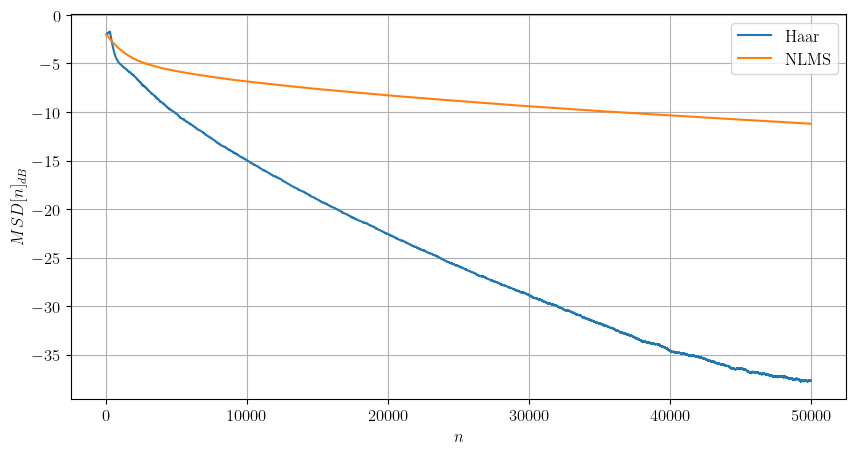

In [7]:
plt.figure(figsize=(10, 5))

for name in results:
    plt.plot(10*np.log10(results[name]["MSD"]), label=name)

plt.xlabel("$$n$$")
plt.ylabel("$$MSD[n]_{dB}$$")
plt.grid()
plt.legend()
plt.savefig('MSD.pdf')
plt.show()

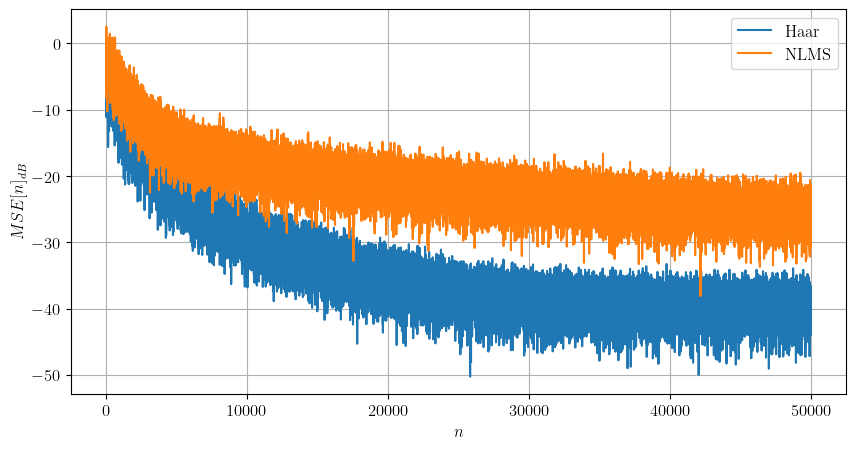

In [8]:
plt.figure(figsize=(10, 5))

for name in results:
    plt.plot(10*np.log10(results[name]["MSE"]), label=name)

plt.xlabel("$$n$$")
plt.ylabel("$$MSE[n]_{dB}$$")
plt.grid()
plt.legend()
plt.savefig('MSE.pdf')
plt.show()

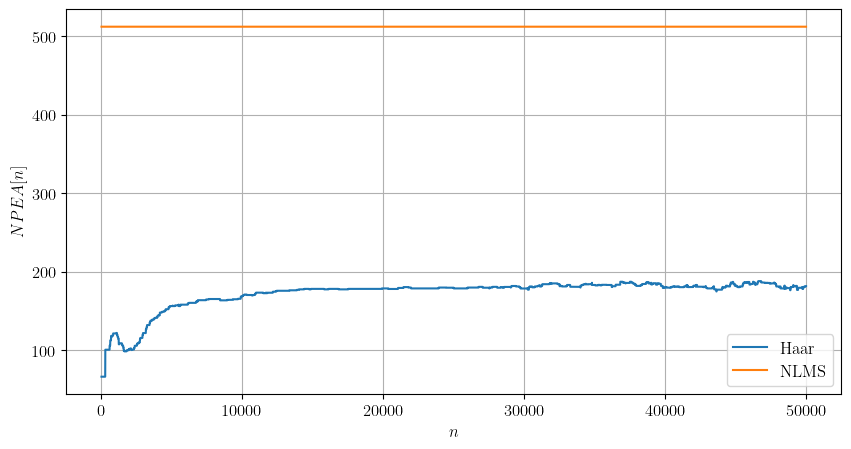

In [9]:
plt.figure(figsize=(10, 5))

for name in results:
    plt.plot(results[name]["NPEA"], label=name)

plt.xlabel("$$n$$")
plt.ylabel("$$NPEA[n]$$")
plt.grid()
plt.legend()
plt.savefig('NPEA.pdf')
plt.show()

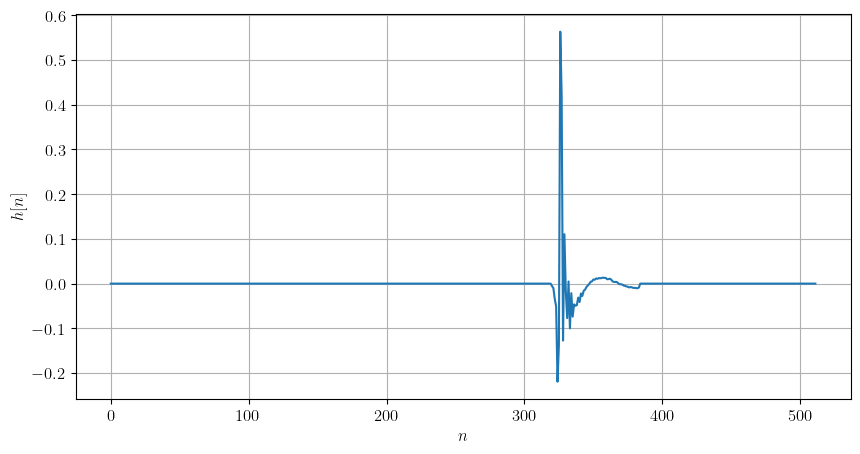

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(unknown_system)

plt.xlabel("$$n$$")
plt.ylabel("$$h[n]$$")
plt.grid()
plt.savefig('h.pdf')
plt.show()

In [11]:
np.savez_compressed("m1.npz", results=results)